In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

ipath = '../../inputs/EMT/'

F_MENAGES = ipath + "menages.csv"
F_PERSONNES = ipath + "personnes.csv"
F_DEPLACEMENTS = ipath + "deplacements.csv"

ZONE_REPONSE = "DP2"
PONDERER = True

In [3]:
def lire_csv(chemin):
    df = pd.read_csv(
        chemin,
        sep=";",
        dtype="string",
        encoding="utf-8-sig"
    )
    df.columns = df.columns.str.strip()
    return df

def nettoyer_code(serie):
    return (
        serie.astype("string")
             .str.strip()
             .str.replace(r"\.0$", "", regex=True)
    )

menages_brut = lire_csv(F_MENAGES)
personnes_brut = lire_csv(F_PERSONNES)
deplacements_brut = lire_csv(F_DEPLACEMENTS)

print("Ménages :", menages_brut.shape)
print("Personnes :", personnes_brut.shape)
print("Déplacements :", deplacements_brut.shape)
print("\nChamps déplacements :", deplacements_brut.columns.tolist())

Ménages : (8020, 54)
Personnes : (16109, 51)
Déplacements : (40594, 27)

Champs déplacements : ['DP1', 'DP2', 'DPRO', 'ECH', 'PER', 'NDEP', 'D2A', 'D2B', 'D3', 'D4', 'D5A', 'D5B', 'D6', 'D7', 'D8', 'D8C', 'D9', 'MODP', 'MOIP', 'DOIB', 'DIST', 'DISP', 'DL10', 'DL11', 'DFIN', 'D11', 'ND11']


In [ ]:
menages = menages_brut[
    ["MP2", "MPRO", "ECH", "COEM"]
].rename(
    columns={"MP2": "zone_residence", "MPRO": "provenance"}
).copy()

personnes = personnes_brut[
    ["PP2", "PPRO", "ECH", "PER", "P3", "P9"]
].rename(
    columns={"PP2": "zone_residence", "PPRO": "provenance"}
).copy()

deplacements = deplacements_brut[
    ["DP2", "DPRO", "ECH", "PER", "NDEP", "D4", "D3"]
].rename(
    columns={
        "DP2": "zone_residence",
        "DPRO": "provenance",
        "D3": "zone_origine"
    }
).copy()

cles_menage = ["zone_residence", "provenance", "ECH"]
cles_personne = cles_menage + ["PER"]

for df in (menages, personnes, deplacements):
    for col in ["zone_residence", "provenance", "ECH"]:
        df[col] = nettoyer_code(df[col])

    # MP2, PP2 et DP2 sont supposés être des codes de zone à 9 caractères.
    df["zone_residence"] = df["zone_residence"].str.zfill(9)
    df["provenance"] = df["provenance"].str.zfill(1)
    df["ECH"] = df["ECH"].str.zfill(4)

for df in (personnes, deplacements):
    df["PER"] = nettoyer_code(df["PER"]).str.zfill(2)

personnes["P3"] = nettoyer_code(personnes["P3"])
personnes["P9"] = nettoyer_code(personnes["P9"])
deplacements["NDEP"] = nettoyer_code(deplacements["NDEP"])
deplacements["zone_origine"] = nettoyer_code(deplacements["zone_origine"])

menages["poids"] = pd.to_numeric(
    menages["COEM"].str.strip().str.replace(",", ".", regex=False),
    errors="coerce"
)

### Comment répartir les ménages selon la CSP? de façon probabiliste?

In [5]:
if menages.duplicated(cles_menage).any():
    raise ValueError("Identifiants ménage dupliqués; vérifier les clés.")

if personnes.duplicated(cles_personne).any():
    raise ValueError("Identifiants personne dupliqués; vérifier les clés.")

recodage_p9 = {
    "5": "CSP-", "6": "CSP-", "7": "CSP-", "8": "CSP-", "9": "CSP-",
    "1": "CSP",  "2": "CSP",  "4": "CSP",
    "3": "CSP+"
}

reference = personnes.loc[personnes["P3"].eq("1")].copy()

if reference.duplicated(cles_menage).any():
    raise ValueError("Plusieurs personnes de référence dans un même ménage.")

reference["csp"] = reference["P9"].map(recodage_p9)
reference = reference.dropna(subset=["csp"])

taille = (
    personnes.groupby(cles_menage)["PER"]
    .nunique()
    .rename("nb_personnes")
    .reset_index()
)

taille["taille"] = np.where(
    taille["nb_personnes"] >= 5,
    "5+",
    taille["nb_personnes"].astype("Int64").astype("string")
)

menages_classes = (
    menages[cles_menage + ["poids"]]
    .merge(
        reference[cles_menage + ["csp"]],
        on=cles_menage,
        how="inner",
        validate="one_to_one"
    )
    .merge(
        taille[cles_menage + ["taille"]],
        on=cles_menage,
        how="left",
        validate="one_to_one"
    )
)

print("Ménages classés :", len(menages_classes))
print("\nEffectifs non pondérés par CSP et taille :")
print(
    menages_classes.groupby(["csp", "taille"], observed=True)
                   .size()
                   .unstack("taille", fill_value=0)
)

Ménages classés : 8015

Effectifs non pondérés par CSP et taille :
taille     1     2    3    4   5+
csp                              
CSP      904  1083  297  244   66
CSP+     500   783  209  238   55
CSP-    1662  1240  336  285  113


In [6]:
deplacements["D4_num"] = pd.to_numeric(
    deplacements["D4"],
    errors="coerce"
)

dep_matin = deplacements.loc[
    (deplacements["D4_num"] >= 700)
    & (deplacements["D4_num"] < 900)
].copy()

cles_dep = cles_personne + ["NDEP"]
dep_avec_numero = dep_matin.loc[dep_matin["NDEP"].notna()]

doublons_dep = dep_avec_numero.duplicated(cles_dep).sum()
print("Déplacements dans la plage horaire :", len(dep_matin))
print("Clés personne + NDEP répétées :", doublons_dep)

if doublons_dep > 0:
    raise ValueError(
        "Des clés personne + NDEP sont répétées. Vérifier ces lignes "
        "avant de continuer."
    )

dep_matin["zone_modele"] = dep_matin["zone_residence"]


Déplacements dans la plage horaire : 6431
Clés personne + NDEP répétées : 0


In [7]:
ordre_csp = ["CSP-", "CSP", "CSP+"]
ordre_taille = ["1", "2", "3", "4", "5+"]
cellules = [(csp, t) for csp in ordre_csp for t in ordre_taille]

# X : nombres de ménages par zone de résidence et cellule CSP × taille
menages_classes = menages_classes.copy()

if PONDERER:
    menages_classes = menages_classes.loc[
        menages_classes["poids"].notna() & (menages_classes["poids"] > 0)
    ].copy()
    menages_classes["contribution_X"] = menages_classes["poids"]
else:
    menages_classes["contribution_X"] = 1.0

x_long = (
    menages_classes.groupby(
        ["zone_residence", "csp", "taille"],
        observed=True
    )["contribution_X"]
    .sum()
    .rename("nb_menages")
    .reset_index()
)

x_large = x_long.pivot_table(
    index="zone_residence",
    columns=["csp", "taille"],
    values="nb_menages",
    aggfunc="sum",
    fill_value=0
)

colonnes_cellules = pd.MultiIndex.from_tuples(
    cellules, names=["csp", "taille"]
)
x_large = x_large.reindex(columns=colonnes_cellules, fill_value=0)

noms_x = [f"x_{i:02d}" for i in range(1, 16)]
cellule_par_variable = dict(zip(noms_x, cellules))
x_large.columns = noms_x
x_large.index.name = "zone"

# Rattacher les déplacements à leur ménage pour récupérer le poids COEM.
dep_avec_menage = (
    dep_matin
    .merge(
        personnes[cles_personne],
        on=cles_personne,
        how="left",
        validate="many_to_one"
    )
    .merge(
        menages[cles_menage + ["poids"]],
        on=cles_menage,
        how="left",
        validate="many_to_one"
    )
)

if PONDERER:
    y_source = dep_avec_menage.dropna(subset=["poids"]).copy()
    y_zone = y_source.groupby("zone_modele")["poids"].sum()
else:
    y_zone = dep_matin.groupby("zone_modele").size()

y_zone.index.name = "zone"
y_zone.name = "deplacements_observes"

# Comparer les codes D3 (ou DP2) aux codes MP2
codes_x = set(x_large.index.astype("string"))
codes_y = set(y_zone.index.astype("string"))

print("Zones avec ménages :", len(codes_x))
print("Zones avec déplacements :", len(codes_y))
print("Codes communs :", len(codes_x & codes_y))
print("Codes ménage sans déplacement :", len(codes_x - codes_y))
print("Codes déplacement sans ménage résident associé :", len(codes_y - codes_x))

if len(codes_x & codes_y) == 0:
    raise ValueError(
        "Aucun code commun entre MP2 et la zone de réponse choisie. "
        "Vérifier que les deux champs utilisent le même zonage et le même format."
    )

# Une ligne par code de zone; les ménages sans déplacement observé ont y = 0
donnees_zone = x_large.join(y_zone, how="outer").fillna(0)
donnees_zone.index.name = "zone"

display(donnees_zone.head())

Zones avec ménages : 821
Zones avec déplacements : 708
Codes communs : 708
Codes ménage sans déplacement : 113
Codes déplacement sans ménage résident associé : 0


,x_01,x_02,x_03,x_04,x_05,x_06,x_07,x_08,x_09,x_10,x_11,x_12,x_13,x_14,x_15,deplacements_observes
zone,,,,,,,,,,,,,,,,
161001000,425.3055,0.0,0.0,174.1106,0.0,192.3329,0.0,0.0,0.0,0.0,41.18439,0.0,0.0,0.0,0.0,773.5267
161002000,179.0419,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,227.3306,0.0,0.0,0.0,0.0,58.4741
161003000,616.2239,112.9722,0.0,0.0,0.0,236.2041,161.3061,0.0,0.0,0.0,0.0,143.12337,0.0,0.0,0.0,285.24198
161004000,409.5715,0.0,0.0,0.0,0.0,288.27303,113.5169,0.0,0.0,0.0,144.0728,0.0,153.493,0.0,0.0,564.5757
161005000,887.625,0.0,0.0,0.0,245.2384,218.07434,0.0,0.0,0.0,0.0,80.85825,201.0342,0.0,0.0,0.0,2094.9131


In [8]:
X = donnees_zone[noms_x].astype(float)
y = donnees_zone["deplacements_observes"].astype(float)

zones_avec_menages = X.sum(axis=1) > 0
print("Zones utilisées pour ajuster le modèle :", zones_avec_menages.sum())
print("Zones sans ménage associé :", (~zones_avec_menages).sum())

X_fit = X.loc[zones_avec_menages]
y_fit = y.loc[zones_avec_menages]

if len(X_fit) <= 15:
    raise ValueError("Il faut plus de 15 zones avec ménages pour ajuster le modèle.")

rang = np.linalg.matrix_rank(X_fit.to_numpy())
print(f"Rang de la matrice X : {rang} sur 15")

if rang < 15:
    raise ValueError(
        "Les 15 prédicteurs ne sont pas indépendants dans ces données; "
        "les 15 coefficients ne peuvent pas être estimés séparément."
    )

# X ne contient pas de constante : la régression passe par l'origine
modele = sm.OLS(y_fit, X_fit).fit(cov_type="HC3")

print(modele.summary())

table_coefficients = pd.DataFrame({
    "variable": noms_x,
    "cellule": [
        f"{csp}, taille {t}"
        for csp, t in [cellule_par_variable[v] for v in noms_x]
    ],
    "coefficient": modele.params[noms_x].to_numpy()
})

display(table_coefficients)

donnees_zone["deplacements_predits"] = modele.predict(X)

# Pour un modèle sans constante, afficher le R² non centré et le R² centré
y_pred_fit = donnees_zone.loc[zones_avec_menages, "deplacements_predits"]
ss_res = np.sum((y_fit - y_pred_fit) ** 2)

ss_tot_centre = np.sum((y_fit - y_fit.mean()) ** 2)
ss_tot_non_centre = np.sum(y_fit ** 2)

r2_centre = 1 - ss_res / ss_tot_centre
r2_non_centre = 1 - ss_res / ss_tot_non_centre

print(f"R² centré     : {r2_centre:.3f}")
print(f"R² non centré : {r2_non_centre:.3f}")

Zones utilisées pour ajuster le modèle : 821
Zones sans ménage associé : 0
Rang de la matrice X : 15 sur 15
                                  OLS Regression Results                                  
Dep. Variable:     deplacements_observes   R-squared (uncentered):                   0.903
Model:                               OLS   Adj. R-squared (uncentered):              0.901
Method:                    Least Squares   F-statistic:                              217.3
Date:                   Fri, 27 Nov 2026   Prob (F-statistic):                   6.62e-271
Time:                           18:05:40   Log-Likelihood:                         -6100.1
No. Observations:                    821   AIC:                                  1.223e+04
Df Residuals:                        806   BIC:                                  1.230e+04
Df Model:                             15                                                  
Covariance Type:                     HC3                                 

,variable,cellule,coefficient
0,x_01,"CSP-, taille 1",0.272992
1,x_02,"CSP-, taille 2",0.264595
2,x_03,"CSP-, taille 3",2.092937
3,x_04,"CSP-, taille 4",2.774823
4,x_05,"CSP-, taille 5+",2.945561
5,x_06,"CSP, taille 1",0.560113
6,x_07,"CSP, taille 2",0.646122
7,x_08,"CSP, taille 3",1.743864
8,x_09,"CSP, taille 4",2.512497
9,x_10,"CSP, taille 5+",3.367907


R² centré     : 0.830
R² non centré : 0.903


In [12]:
table_coefficients['csp'] = table_coefficients['cellule'].apply(lambda x: x.split(',')[0])
table_coefficients['size'] = table_coefficients['cellule'].apply(lambda x: x.split(',')[1].replace(' taille ', ''))
table_coefficients.rename(columns={'coefficient': 'gen_factor'})[['gen_factor', 'size', 'csp']].to_csv(ipath + '../socio_eco/generation_factors.csv')

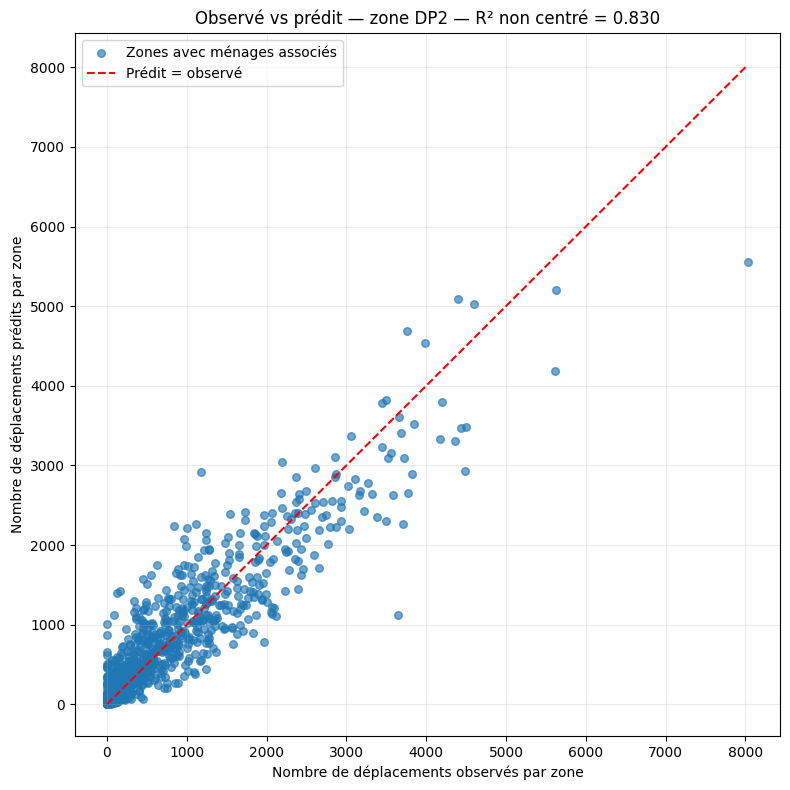

In [9]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    donnees_zone.loc[zones_avec_menages, "deplacements_observes"],
    donnees_zone.loc[zones_avec_menages, "deplacements_predits"],
    alpha=0.65,
    s=30,
    label="Zones avec ménages associés"
)

zones_sans_menages = ~zones_avec_menages

if zones_sans_menages.any():
    ax.scatter(
        donnees_zone.loc[zones_sans_menages, "deplacements_observes"],
        donnees_zone.loc[zones_sans_menages, "deplacements_predits"],
        marker="x",
        s=45,
        label="Zones sans ménage associé"
    )

minimum = min(
    0,
    float(donnees_zone["deplacements_observes"].min()),
    float(donnees_zone["deplacements_predits"].min())
)
maximum = max(
    float(donnees_zone["deplacements_observes"].max()),
    float(donnees_zone["deplacements_predits"].max())
)

ax.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--",
    color="red",
    label="Prédit = observé"
)

ax.set_xlabel("Nombre de déplacements observés par zone")
ax.set_ylabel("Nombre de déplacements prédits par zone")
ax.set_title(
    f"Observé vs prédit — zone {ZONE_REPONSE} — R² non centré = {r2_centre:.3f}"
)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()